# Separate simulation figures and LFP autocorrelation

Plots results from Simulate_dynamics.py.
Run from the folder containing your `.mat` files, or change `DATA_DIR` below.
For each condition this notebook displays and saves **three separate figures**:

1. **LFP traces:** square axes, channel-wise z scores.
2. **Spike raster + population firing rates:** a square plotting region.
3. **LFP ACF:** square axes; mean of the per-channel normalized autocorrelations.

PDF and SVG are saved by default. The selected iteration, condition mapping, population sizes, colors, and time constants come from the supplied notebook. No filtering or rate smoothing is added.


In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


## Configuration
`ITERATION_TO_PLOT = 2` selects the second available LFP file, as in your original notebook (it is not a duration in milliseconds). LFP/rate file numbering starts at `i0`; spike file numbering starts at `i1`.

Square means equal physical width and height of the plotting box, not equal numerical x/y scales. The combined figure uses a square outer plotting region; its individual panels have unequal heights as requested.

In [2]:
DATA_DIR = Path(".")
OUTPUT_DIR = DATA_DIR / "figures_separate"
SAVE_FORMATS = ("pdf", "svg")
SHOW_FIGURES = True

ITERATION_TO_PLOT = 2  

CONDITIONS = {0: 0.70, 1: 0.85, 2: 1.40}
SEGMENT_DURATION_MS = 500.0
LFP_DT_MS = 1.0
WARMUP_MS = 100.0
N_E = 800
N_I = 200

LFP_TRACE_OFFSET = 0.0

ACF_MAX_LAG_MS = 150.0  # capped at the selected segment's length minus one sample
ACF_SHOW_CHANNELS = True
SPIKE_ITERATION_OFFSET = 1
# Original auto heuristics; override if you know how your files were saved.
SPIKE_TIME_UNIT = "auto"       # "auto", "s", or "ms"
SPIKE_TIME_REFERENCE = "auto"  # "auto", "global", or "local"

plt.rcParams.update({"axes.grid": False, "svg.fonttype": "none"})


In [3]:
def load_data_vector(path, key="data"):
    mat = loadmat(path, squeeze_me=True)
    if key not in mat:
        raise KeyError(f"{path.name} does not contain variable {key!r}")
    return np.asarray(mat[key])


def discover_files(prefix, j_value):
    """Return [(iteration_number, path), ...] sorted by iteration."""
    pattern = re.compile(rf"^{re.escape(prefix)}_i(\d+)_J{j_value}\.mat$")
    found = []
    for path in DATA_DIR.glob(f"{prefix}_i*_J{j_value}.mat"):
        match = pattern.match(path.name)
        if match:
            found.append((int(match.group(1)), path))
    return sorted(found)


def as_time_by_channel(array):
    """Normalize LFP data to shape (time, channels)."""
    array = np.asarray(array, dtype=float)
    if array.ndim == 1:
        return array[:, None]
    if array.ndim != 2:
        raise ValueError(f"Expected a 1D or 2D LFP array, got shape {array.shape}")
    # A 500 ms LFP segment normally has 500 time samples and fewer channels.
    expected_n = int(round(SEGMENT_DURATION_MS / LFP_DT_MS))
    if array.shape[1] == expected_n and array.shape[0] != expected_n:
        array = array.T
    elif array.shape[0] < array.shape[1] and array.shape[0] != expected_n:
        warnings.warn(f"Assuming shape {array.shape} is channels x time; transposing.")
        array = array.T
    return array


def zscore_channels(data):
    mean = np.nanmean(data, axis=0, keepdims=True)
    std = np.nanstd(data, axis=0, ddof=0, keepdims=True)
    std[std == 0] = 1.0
    return (data - mean) / std


def to_milliseconds(times):
    times = np.asarray(times, dtype=float).ravel()
    if SPIKE_TIME_UNIT == "s":
        return 1000.0 * times
    if SPIKE_TIME_UNIT == "ms":
        return times
    if SPIKE_TIME_UNIT != "auto":
        raise ValueError("SPIKE_TIME_UNIT must be 'auto', 's', or 'ms'")
    # Original heuristic: small values are assumed to be seconds.
    return 1000.0 * times if times.size and np.nanmax(np.abs(times)) < 100 else times


def load_spikes_for_condition(j_value):
    """Merge E/I spike files and return times relative to the analyzed run."""
    populations = {}
    for pop in ("E", "I"):
        time_files = discover_files(f"{pop}_spike_times", j_value)
        id_files = dict(discover_files(f"{pop}_spike_id", j_value))
        pieces = []
        for order, (iteration, time_path) in enumerate(time_files):
            if iteration not in id_files:
                warnings.warn(f"Missing ID file paired with {time_path.name}")
                continue
            times_ms = to_milliseconds(load_data_vector(time_path, "SpikeTimes"))
            ids = load_data_vector(id_files[iteration], "SpikeId").astype(int).ravel()
            if times_ms.size != ids.size:
                raise ValueError(f"Mismatched spike times/IDs in {time_path.name}")
            n = times_ms.size
            pieces.append({"order": order, "iteration": iteration,
                           "times_ms": times_ms[:n], "ids": ids[:n]})

        # Detect whether timestamps restart inside each saved segment.
        maxima = [np.nanmax(p["times_ms"]) for p in pieces if p["times_ms"].size]
        local_times = bool(maxima) and max(maxima) <= 1.25 * SEGMENT_DURATION_MS
        if SPIKE_TIME_REFERENCE not in {"auto", "global", "local"}:
            raise ValueError("SPIKE_TIME_REFERENCE must be 'auto', 'global', or 'local'")
        if SPIKE_TIME_REFERENCE != "auto":
            local_times = SPIKE_TIME_REFERENCE == "local"
        print(f"J{j_value} {pop}: spike reference = {'local' if local_times else 'global'}")
        for p in pieces:
            if local_times:
                p["times_ms"] = p["times_ms"] + (p["iteration"] - SPIKE_ITERATION_OFFSET) * SEGMENT_DURATION_MS
            else:
                p["times_ms"] = p["times_ms"] - WARMUP_MS

        populations[pop] = pieces
    return populations


def summarize_available_files():
    rows = []
    for j_value, drive in CONDITIONS.items():
        rows.append({
            "J": j_value,
            "drive": drive,
            "LFP iterations": [i for i, _ in discover_files("LFP", j_value)],
            "E-rate iterations": [i for i, _ in discover_files("RATE_E", j_value)],
            "I-rate iterations": [i for i, _ in discover_files("RATE_I", j_value)],
            "E-spike iterations": [i for i, _ in discover_files("E_spike_times", j_value)],
            "I-spike iterations": [i for i, _ in discover_files("I_spike_times", j_value)],
        })
    return rows


## Autocorrelation definition
For each channel, subtract its mean over the selected iteration, then compute

$$\mathrm{ACF}_c(k)=\frac{\sum_{t=0}^{N-k-1}(x_c(t)-\bar{x}_c)(x_c(t+k)-\bar{x}_c)}{\sum_{t=0}^{N-1}(x_c(t)-\bar{x}_c)^2}.$$

This is the normalized **biased** autocorrelation estimator, with ACF(0) = 1. It uses a fixed denominator, without an `N/(N-k)` overlap correction. The black curve is the equal-weight channel average; faint curves show individual channels, not uncertainty. ACFs are computed on the raw saved LFP after demeaning, without filtering, and without joining iterations. Constant channels and channels containing nonfinite values are excluded with a warning.

In [4]:
def lfp_autocorrelation(lfp, dt_ms, max_lag_ms):
    data = np.asarray(lfp, dtype=float)
    if data.ndim != 2 or data.shape[0] < 2:
        raise ValueError("ACF requires at least two time samples in a time-by-channel array")
    if dt_ms <= 0 or max_lag_ms < 0:
        raise ValueError("dt_ms must be positive and max_lag_ms nonnegative")
    finite = np.all(np.isfinite(data), axis=0)
    centered = data[:, finite] - data[:, finite].mean(axis=0, keepdims=True)
    energy = np.sum(centered**2, axis=0)
    varying = energy > 0
    excluded = data.shape[1] - np.count_nonzero(varying)
    if excluded:
        warnings.warn(f"ACF: excluded {excluded} constant/nonfinite channel(s)")
    centered, energy = centered[:, varying], energy[varying]
    if not energy.size:
        raise ValueError("No finite, nonconstant LFP channels available for ACF")
    n_samples = data.shape[0]
    max_lag = min(int(np.floor(max_lag_ms / dt_ms)), n_samples - 1)
    # Zero padding avoids circular correlation.
    n_fft = 1 << (2 * n_samples - 1).bit_length()
    spectrum = np.fft.rfft(centered, n=n_fft, axis=0)
    corr = np.fft.irfft(spectrum * spectrum.conj(), n=n_fft, axis=0)
    acf = corr[:max_lag + 1] / energy[None, :]
    return np.arange(max_lag + 1) * dt_ms, acf


def save_and_display(fig, stem):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for extension in SAVE_FORMATS:
        path = OUTPUT_DIR / f"{stem}.{extension}"
        fig.savefig(path, dpi=300, facecolor="white")
        print(f"Saved {path}")
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)


def square_axes():
    fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")
    ax.set_box_aspect(1)
    return fig, ax


def plot_lfp(lfp, title, stem):
    lfp_z = zscore_channels(lfp)
    time_ms = np.arange(lfp.shape[0]) * LFP_DT_MS
    fig, ax = square_axes()

    colors = plt.get_cmap("tab10")(np.arange(lfp.shape[1]) % 10)
    for channel in range(lfp.shape[1]):
        ax.plot(time_ms, lfp_z[:, channel] + LFP_TRACE_OFFSET * channel,
                color=colors[channel], lw=1.5, alpha=0.65)

    ax.set(xlim=(200, 500), xlabel="Time (ms)", ylabel="LFP amplitude (z score)")
    if LFP_TRACE_OFFSET:
        ax.set_yticks([])
        ax.set_ylabel("LFP (z score, vertically offset)")
    save_and_display(fig, stem + "_lfp")


def plot_raster_rates(spikes, iteration, rates, title, stem):
    # Equal figure dimensions and equal outer plot width/height give a square
    # combined plotting region. GridSpec preserves the exact 2:1 axes heights.
    fig = plt.figure(figsize=(6.5, 6.5))
    gs = fig.add_gridspec(2, 1, left=0.16, right=0.94, bottom=0.13, top=0.91,
                         height_ratios=[2, 1], hspace=0.08)
    ax_raster = fig.add_subplot(gs[0])
    ax_rate = fig.add_subplot(gs[1], sharex=ax_raster)
    spike_iteration = iteration + SPIKE_ITERATION_OFFSET
    for pop, color, offset in (("I", "tab:red", 0), ("E", "black", N_I)):
        selected = [p for p in spikes[pop] if p["iteration"] == spike_iteration]
        if not selected:
            warnings.warn(f"Missing {pop} spikes for i{spike_iteration}")
        for piece in selected:
            times = piece["times_ms"] - iteration * SEGMENT_DURATION_MS

            raw_times = np.asarray(piece["times_ms"])
            print(
                f"{pop}: iteration={iteration}, spike_iteration={spike_iteration}, "
                f"segment={SEGMENT_DURATION_MS} ms"
            )
            if times.size:
                print(
                    f"Raw: {raw_times.min():.1f}–{raw_times.max():.1f} ms; "
                    f"shifted: {times.min():.1f}–{times.max():.1f} ms; "
                    f"spikes in displayed window: "
                    f"{np.count_nonzero((times >= 200) & (times <= 500) & (times < SEGMENT_DURATION_MS))}"
                )
            

            keep = (times >= 0) & (times < SEGMENT_DURATION_MS)
            ax_raster.scatter(times[keep], piece["ids"][keep] + offset,
                              s=7.0, c=color, linewidths=0, rasterized=True,
                              label=pop)
    ax_raster.set(ylim=(-0.5, N_I + N_E - 0.5), ylabel="Neuron", title=title)
    ax_raster.tick_params(axis="x", bottom=False, labelbottom=False)
    handles, labels = ax_raster.get_legend_handles_labels()
    if handles:
        ax_raster.legend(frameon=False, markerscale=4, loc="upper right")
    for pop, color in (("E", "black"), ("I", "tab:red")):
        rate = rates[pop]
        if rate.size:
            time_ms = np.arange(rate.size) * SEGMENT_DURATION_MS / rate.size
            ax_rate.plot(time_ms, rate, color=color, lw=0.9, label=pop)
   # ax_rate.set(xlim=(0, 300), xlabel="Time (ms)", ylabel="Rate (Hz)")
    ax_rate.set(xlim=(200, 500), xlabel="Time (ms)", ylabel="Rate (Hz)")
    if any(rate.size for rate in rates.values()):
        ax_rate.legend(frameon=False, loc="upper right", ncol=2)
    save_and_display(fig, stem + "_raster_rates")


def plot_acf(lfp, title, stem):
    lag_ms, acf = lfp_autocorrelation(lfp, LFP_DT_MS, ACF_MAX_LAG_MS)
    fig, ax = square_axes()
    ax.axhline(0, color="0.7", lw=0.7)

    colors = plt.get_cmap("tab10")(np.arange(acf.shape[1]) % 10)
    for channel in range(acf.shape[1]):
        ax.plot(lag_ms, acf[:, channel],
                color=colors[channel], lw=1.5, alpha=0.8)

    ax.set(xlim=(0, lag_ms[-1] if lag_ms[-1] > 0 else LFP_DT_MS),
           ylim=(-1.05, 1.05), xlabel="Lag (ms)",
           ylabel="Normalized LFP ACF", title=title)
    save_and_display(fig, stem + "_lfp_acf")


## Generate and save the figures
Run this cell after setting `DATA_DIR`. The file summary is printed first. Filenames include the condition, drive and actual LFP iteration number to distinguish saved outputs. Re-running the same settings replaces those figures.

{'J': 0, 'drive': 0.7, 'LFP iterations': [0, 1], 'E-rate iterations': [0, 1], 'I-rate iterations': [0, 1], 'E-spike iterations': [1, 2], 'I-spike iterations': [1, 2]}
{'J': 1, 'drive': 0.85, 'LFP iterations': [0, 1], 'E-rate iterations': [0, 1], 'I-rate iterations': [0, 1], 'E-spike iterations': [1, 2], 'I-spike iterations': [1, 2]}
{'J': 2, 'drive': 1.6, 'LFP iterations': [0, 1], 'E-rate iterations': [0, 1], 'I-rate iterations': [0, 1], 'E-spike iterations': [1, 2], 'I-spike iterations': [1, 2]}
J0 E: spike reference = global
J0 I: spike reference = global
Plotting LFP_i1_J0.mat
Saved figures_separate/condition_J0_drive_0.70_i1_lfp.pdf
Saved figures_separate/condition_J0_drive_0.70_i1_lfp.svg


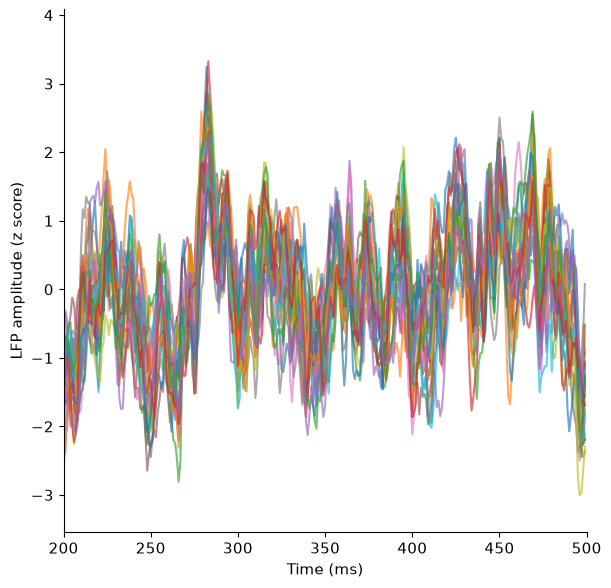

I: iteration=1, spike_iteration=2, segment=500.0 ms
Raw: 506.2–997.5 ms; shifted: 6.2–497.5 ms; spikes in displayed window: 39
E: iteration=1, spike_iteration=2, segment=500.0 ms
Raw: 500.1–995.1 ms; shifted: 0.1–495.1 ms; spikes in displayed window: 82
Saved figures_separate/condition_J0_drive_0.70_i1_raster_rates.pdf
Saved figures_separate/condition_J0_drive_0.70_i1_raster_rates.svg


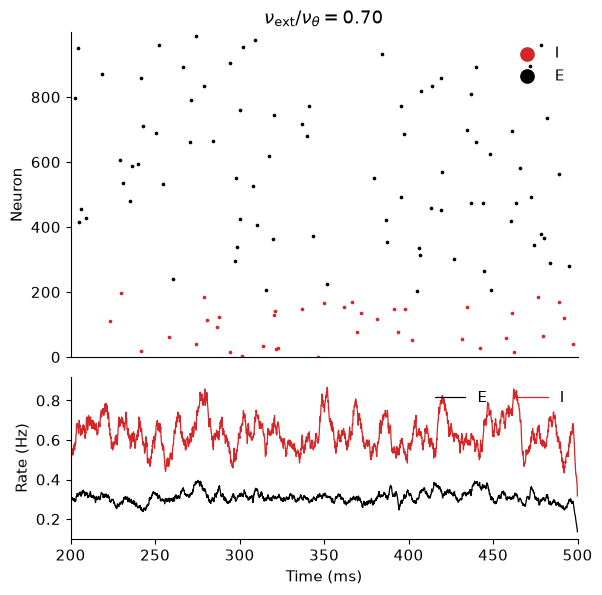

Saved figures_separate/condition_J0_drive_0.70_i1_lfp_acf.pdf
Saved figures_separate/condition_J0_drive_0.70_i1_lfp_acf.svg


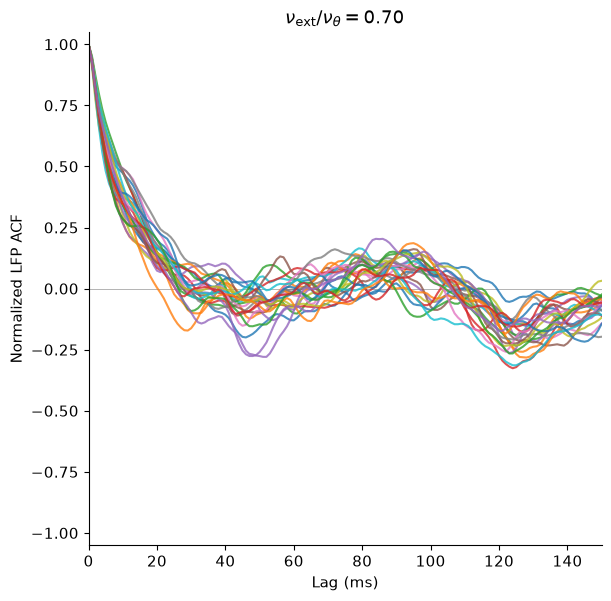

J1 E: spike reference = global
J1 I: spike reference = global
Plotting LFP_i1_J1.mat
Saved figures_separate/condition_J1_drive_0.85_i1_lfp.pdf
Saved figures_separate/condition_J1_drive_0.85_i1_lfp.svg


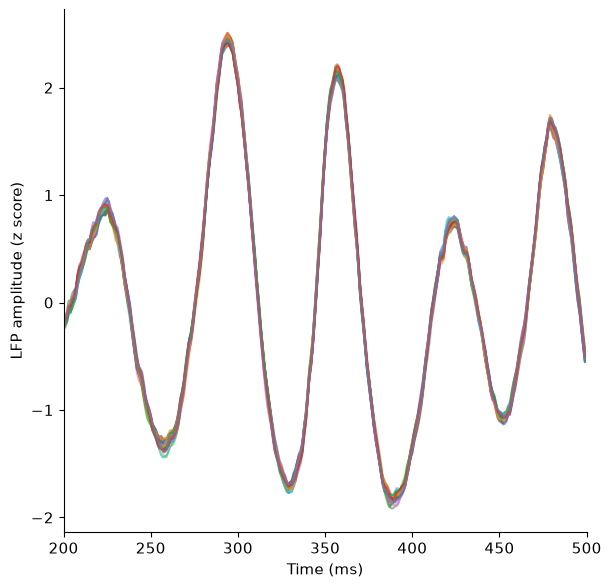

I: iteration=1, spike_iteration=2, segment=500.0 ms
Raw: 500.0–996.4 ms; shifted: 0.0–496.4 ms; spikes in displayed window: 180
E: iteration=1, spike_iteration=2, segment=500.0 ms
Raw: 500.5–999.1 ms; shifted: 0.5–499.1 ms; spikes in displayed window: 300
Saved figures_separate/condition_J1_drive_0.85_i1_raster_rates.pdf
Saved figures_separate/condition_J1_drive_0.85_i1_raster_rates.svg


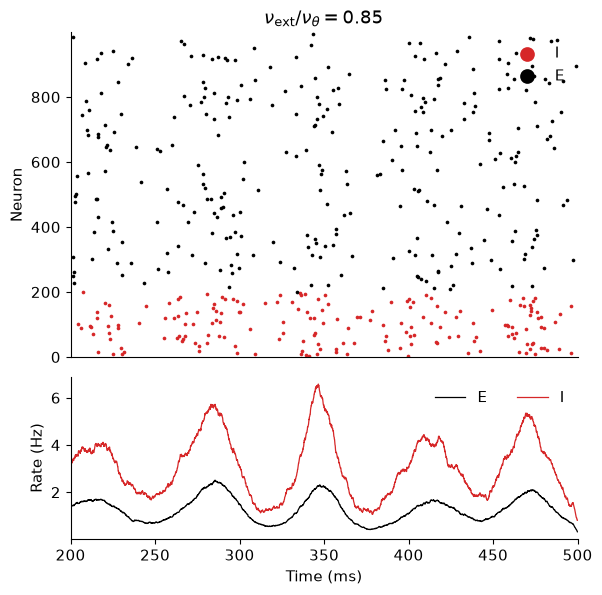

Saved figures_separate/condition_J1_drive_0.85_i1_lfp_acf.pdf
Saved figures_separate/condition_J1_drive_0.85_i1_lfp_acf.svg


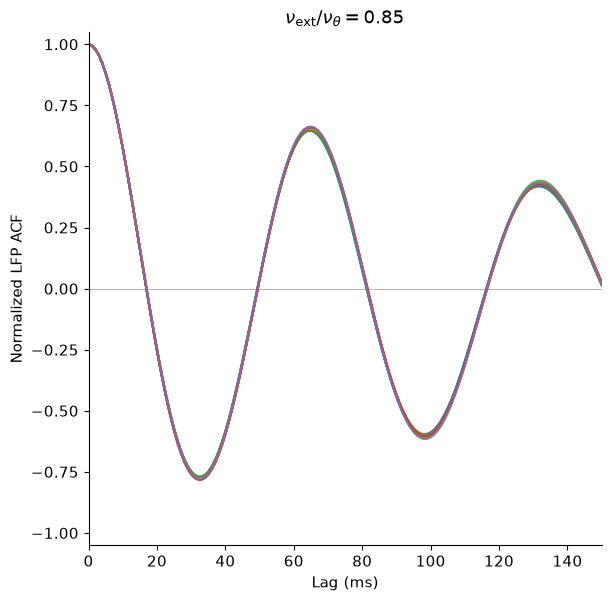

J2 E: spike reference = global
J2 I: spike reference = global
Plotting LFP_i1_J2.mat
Saved figures_separate/condition_J2_drive_1.60_i1_lfp.pdf
Saved figures_separate/condition_J2_drive_1.60_i1_lfp.svg


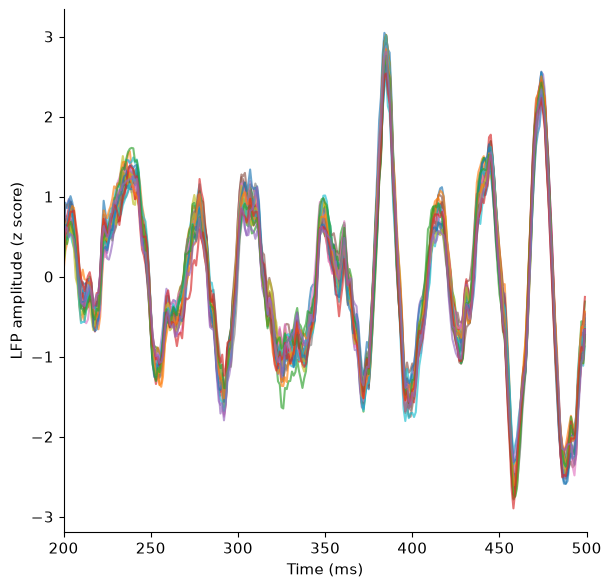

I: iteration=1, spike_iteration=2, segment=500.0 ms
Raw: 501.0–999.9 ms; shifted: 1.0–499.9 ms; spikes in displayed window: 512
E: iteration=1, spike_iteration=2, segment=500.0 ms
Raw: 500.2–999.7 ms; shifted: 0.2–499.7 ms; spikes in displayed window: 412
Saved figures_separate/condition_J2_drive_1.60_i1_raster_rates.pdf
Saved figures_separate/condition_J2_drive_1.60_i1_raster_rates.svg


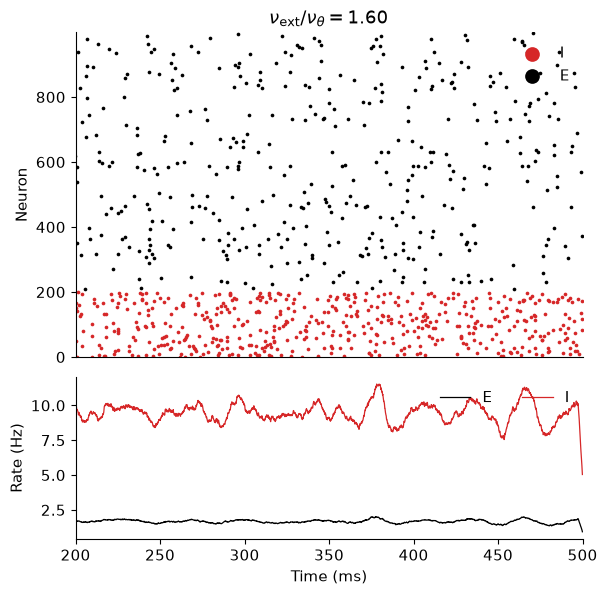

Saved figures_separate/condition_J2_drive_1.60_i1_lfp_acf.pdf
Saved figures_separate/condition_J2_drive_1.60_i1_lfp_acf.svg


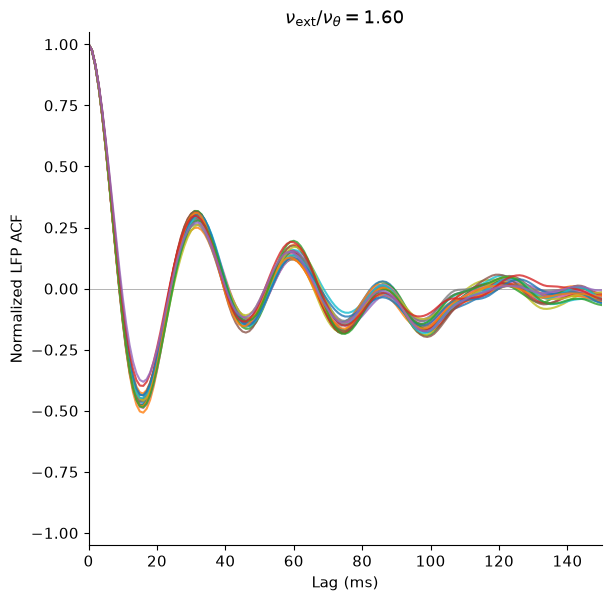

In [5]:
if not isinstance(ITERATION_TO_PLOT, (int, np.integer)) or ITERATION_TO_PLOT < 1:
    raise ValueError("ITERATION_TO_PLOT must be a positive integer")

for row in summarize_available_files():
    print(row)

conditions_plotted = 0
for j_value, drive in CONDITIONS.items():
    lfp_files = discover_files("LFP", j_value)
    if not lfp_files:
        warnings.warn(f"No LFP files for J{j_value}; skipping")
        continue
    if ITERATION_TO_PLOT > len(lfp_files):
        raise ValueError(f"J{j_value} has only {len(lfp_files)} available LFP iterations")
    iteration, lfp_path = lfp_files[ITERATION_TO_PLOT - 1]
    lfp = as_time_by_channel(load_data_vector(lfp_path))
    if not np.isclose(lfp.shape[0] * LFP_DT_MS, SEGMENT_DURATION_MS):
        raise ValueError(f"{lfp_path.name}: sample count conflicts with LFP_DT_MS/SEGMENT_DURATION_MS")
    rates = {}
    for pop in ("E", "I"):
        rate_files = dict(discover_files(f"RATE_{pop}", j_value))
        if iteration in rate_files:
            rates[pop] = np.asarray(load_data_vector(rate_files[iteration]), dtype=float).ravel()
        else:
            rates[pop] = np.array([])
            warnings.warn(f"Missing RATE_{pop}_i{iteration}_J{j_value}.mat")
    spikes = load_spikes_for_condition(j_value)
    title = rf"$\nu_{{\rm ext}}/\nu_\theta={drive:.2f}$"
    stem = f"condition_J{j_value}_drive_{drive:.2f}_i{iteration}"
    print(f"Plotting {lfp_path.name}")
    plot_lfp(lfp, title, stem)
    plot_raster_rates(spikes, iteration, rates, title, stem)
    plot_acf(lfp, title, stem)
    conditions_plotted += 1

if not conditions_plotted:
    raise FileNotFoundError(f"No matching LFP files in {DATA_DIR.resolve()}; set DATA_DIR above")
